# Clasificación tipo BERT (encoder-only)

Se implementa un **Transformer de solo codificador** (familia BERT) para **clasificación de secuencias**: análisis de sentimiento sobre mini-reseñas sintéticas. Se usa el token especial **`[CLS]`** como resumen de la secuencia y una cabeza de clasificación encima.

In [1]:
# --- Dependencias (en Colab ya vienen; si no) ---
!pip install torch matplotlib -q

import math, random, time
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0); random.seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

Dispositivo: cuda


## Bloques del Transformer desde cero

In [2]:
# ======== Bloques del Transformer construidos DESDE CERO ========
# Cada pieza corresponde a un concepto de la Unidad II.

def scaled_dot_product_attention(Q, K, V, mask=None):
    """Atención escalada por producto punto. Devuelve la salida y los pesos de atención."""
    d_k = Q.size(-1)
    scores = (Q @ K.transpose(-2, -1)) / math.sqrt(d_k)      # QKᵀ / √d_k
    if mask is not None:
        scores = scores.masked_fill(mask == 0, float("-inf"))  # padding o máscara causal
    attn = torch.softmax(scores, dim=-1)                      # pesos de atención (suman 1)
    return attn @ V, attn

class MultiHeadAttention(nn.Module):
    """h cabezas en paralelo: proyecta Q,K,V, aplica atención por cabeza y concatena (Wo)."""
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.d_k = n_heads, d_model // n_heads
        self.Wq = nn.Linear(d_model, d_model); self.Wk = nn.Linear(d_model, d_model)
        self.Wv = nn.Linear(d_model, d_model); self.Wo = nn.Linear(d_model, d_model)
    def forward(self, q, k, v, mask=None):
        B = q.size(0)
        split = lambda x: x.view(B, -1, self.h, self.d_k).transpose(1, 2)   # (B,h,L,d_k)
        Q, K, V = split(self.Wq(q)), split(self.Wk(k)), split(self.Wv(v))
        if mask is not None: mask = mask.unsqueeze(1)                       # (B,1,Lq,Lk)
        out, attn = scaled_dot_product_attention(Q, K, V, mask)
        out = out.transpose(1, 2).contiguous().view(B, -1, self.h * self.d_k)
        return self.Wo(out), attn                                          # attn: (B,h,Lq,Lk)

class PositionwiseFFN(nn.Module):
    """Red feed-forward position-wise: Linear → ReLU → Linear."""
    def __init__(self, d_model, d_ff):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Linear(d_ff, d_model))
    def forward(self, x): return self.net(x)

class PositionalEncoding(nn.Module):
    """Codificación posicional sinusoidal (se suma al embedding)."""
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0)/d_model))
        pe[:, 0::2] = torch.sin(pos*div); pe[:, 1::2] = torch.cos(pos*div)
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x): return x + self.pe[:, :x.size(1)]

class EncoderLayer(nn.Module):
    """Self-attention + FFN, cada subcapa con residual + LayerNorm."""
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attn = MultiHeadAttention(d_model, n_heads); self.ffn = PositionwiseFFN(d_model, d_ff)
        self.n1, self.n2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model); self.drop = nn.Dropout(dropout)
    def forward(self, x, mask=None):
        a, attn = self.attn(x, x, x, mask); x = self.n1(x + self.drop(a))
        x = self.n2(x + self.drop(self.ffn(x)));  return x, attn

class DecoderLayer(nn.Module):
    """Masked self-attention + cross-attention + FFN (residual + LayerNorm)."""
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, n_heads)
        self.cross_attn = MultiHeadAttention(d_model, n_heads)
        self.ffn = PositionwiseFFN(d_model, d_ff)
        self.n1, self.n2, self.n3 = (nn.LayerNorm(d_model) for _ in range(3)); self.drop = nn.Dropout(dropout)
    def forward(self, x, memory, tgt_mask=None, src_mask=None):
        a, sa = self.self_attn(x, x, x, tgt_mask);      x = self.n1(x + self.drop(a))
        c, ca = self.cross_attn(x, memory, memory, src_mask); x = self.n2(x + self.drop(c))
        x = self.n3(x + self.drop(self.ffn(x)));         return x, sa, ca

def causal_mask(L, device):
    """Máscara triangular: la posición i solo atiende a ≤ i (autorregresivo)."""
    return torch.tril(torch.ones(L, L, device=device)).bool().unsqueeze(0)

print("Bloques del Transformer listos.")

Bloques del Transformer listos.


## Datos: mini-reseñas sintéticas con sentimiento

Construimos frases a partir de palabras positivas, negativas y neutras. La etiqueta es el sentimiento. Cada secuencia empieza con `[CLS]`.

In [3]:
POS=["excelente","bueno","genial","perfecto","increible","recomendado","eficiente","rapido"]
NEG=["malo","pesimo","lento","defectuoso","horrible","decepcionante","caro","fragil"]
NEU=["el","producto","es","muy","bastante","parece","resulta","llego","aparato"]
CLS,PAD="[CLS]","[PAD]"
vocab=sorted(set([CLS,PAD]+POS+NEG+NEU)); stoi={w:i for i,w in enumerate(vocab)}; V=len(vocab); PADI=stoi[PAD]
L=12
def muestra():
    lab=random.randint(0,1); pool=POS if lab else NEG
    ws=random.choices(NEU,k=random.randint(2,4))+random.choices(pool,k=random.randint(1,2))+random.choices(NEU,k=2)
    random.shuffle(ws); return [CLS]+ws, lab
def enc(ws): ids=[stoi[w] for w in ws][:L]; return ids+[PADI]*(L-len(ids))
data=[muestra() for _ in range(4000)]
X=torch.tensor([enc(w) for w,_ in data]); Y=torch.tensor([l for _,l in data])
Xtr,Ytr,Xte,Yte=X[:3200],Y[:3200],X[3200:],Y[3200:]
print("Ejemplo:",data[0][0],"-> sentimiento",data[0][1])
print("Vocabulario:",V)

Ejemplo: ['[CLS]', 'rapido', 'genial', 'aparato', 'el', 'producto', 'bastante', 'aparato'] -> sentimiento 1
Vocabulario: 27


## Modelo: encoder-only + cabezal sobre `[CLS]`

El encoder contextualiza todos los tokens; tomamos el vector del `[CLS]` (posición 0) como resumen y lo pasamos por una capa lineal a 2 clases.

In [4]:
class BERTcls(nn.Module):
    def __init__(self, V, d=64, h=4, ff=128, nl=2, ncls=2):
        super().__init__()
        self.emb=nn.Embedding(V,d,padding_idx=PADI); self.pe=PositionalEncoding(d)
        self.enc=nn.ModuleList([EncoderLayer(d,h,ff) for _ in range(nl)]); self.head=nn.Linear(d,ncls)
    def forward(self, x, return_attn=False):
        m=(x!=PADI).unsqueeze(1); h=self.pe(self.emb(x)); att=None
        for l in self.enc: h,att=l(h,m)
        logits=self.head(h[:,0])                 # [CLS] = posición 0
        return (logits,att) if return_attn else logits

model=BERTcls(V).to(device)
print("Parámetros:", sum(p.numel() for p in model.parameters()))

Parámetros: 68802


## Entrenamiento y evaluación

In [5]:
opt=torch.optim.Adam(model.parameters(),lr=1e-3); lf=nn.CrossEntropyLoss()
Xtr_,Ytr_=Xtr.to(device),Ytr.to(device); t0=time.time()
for ep in range(8):
    model.train(); perm=torch.randperm(3200)
    for i in range(0,3200,128):
        idx=perm[i:i+128]; logits=model(Xtr_[idx]); loss=lf(logits,Ytr_[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    print(f"época {ep+1}  loss {loss.item():.4f}")
model.eval()
with torch.no_grad(): acc=(model(Xte.to(device)).argmax(1).cpu()==Yte).float().mean().item()
print(f"\nAccuracy test: {acc:.1%}  ({time.time()-t0:.0f}s)")

época 1  loss 0.0579
época 2  loss 0.0005
época 3  loss 0.0003
época 4  loss 0.0003
época 5  loss 0.0003
época 6  loss 0.0002
época 7  loss 0.0002
época 8  loss 0.0002

Accuracy test: 100.0%  (2s)


## Visualización: ¿a qué palabras atiende el `[CLS]`?

Graficamos los pesos de atención de la posición `[CLS]` hacia el resto de la secuencia. El modelo debería concentrar la atención en las palabras de sentimiento.

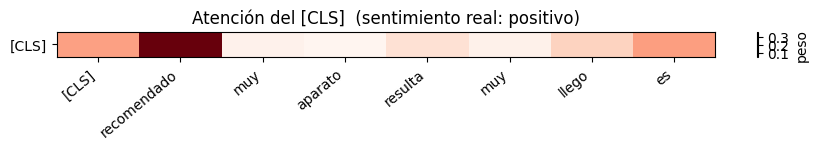

In [6]:
ws,lab=muestra(); ids=torch.tensor([enc(ws)],device=device)
_,att=model(ids,return_attn=True)
cls_attn=att[0].mean(0)[0].detach().cpu().numpy()       # fila del [CLS], promedio de cabezas
toks=[w for w in ws][:L]
plt.figure(figsize=(9,1.6))
plt.imshow(cls_attn[:len(toks)][None,:],cmap="Reds",aspect="auto")
plt.xticks(range(len(toks)),toks,rotation=40,ha="right"); plt.yticks([0],["[CLS]"])
plt.title(f"Atención del [CLS]  (sentimiento real: {'positivo' if lab else 'negativo'})")
plt.colorbar(label="peso"); plt.tight_layout(); plt.show()

## Conclusión

Un encoder-only con un token `[CLS]` resume la secuencia y clasifica. La atención del `[CLS]` se concentra en las palabras informativas — la base de cómo BERT se usa en clasificación.